# Exploratory data analysis: PJM hourly carbon intensity

**Question:** can PJM's lowest-carbon hours be predicted a day ahead well enough to cut emissions from flexible data-center jobs?

**Data:** `data/pjm_hourly.csv`, built by `build_dataset.py` from EIA-930, EIA CO₂ coefficients and heat rates, and NOAA GHCNh. See `README.md` for every column and the method.

**Target:** `ci_prod_kg_per_mwh` is production-based carbon intensity (kg CO₂ per MWh generated in PJM). `ci_cons_kg_per_mwh` is the import-adjusted version, used for the interchange sensitivity check in section 9.

**Conventions:**
- `hour_local` is the Eastern-time hour the interval *starts* (0 = midnight–1am).
- Everything that looks like a forecast in this notebook uses only past data.
- The split used for "out-of-sample" numbers here is train = 2019–2023, test = 2024 onward.

Figures are also saved to `figures/` for the writeup.

## 0. Setup (local or Google Colab)

Run this cell first. On your own computer it does nothing. In Colab it gets the project files, using one of two options:

- `SOURCE = "drive"` (default): the project folder lives in Google Drive. If a teammate shared it with you, right-click it in Drive and choose **Organize → Add shortcut**, putting the shortcut in My Drive. Set `DRIVE_PATH` to the `luke` folder inside it.
- `SOURCE = "github"`: clone the private repo. Before choosing this, add a GitHub personal access token as a Colab secret named `GITHUB_TOKEN` (key icon in the left sidebar).

If `data/pjm_hourly.csv` isn't in the folder, the cell builds it with `build_dataset.py` (several minutes, about 2 GB of downloads).

In [1]:
import os, sys, subprocess
from pathlib import Path

SOURCE = "drive"   # "drive" or "github" (only used in Colab)
DRIVE_PATH = "/content/drive/MyDrive/AC209a-Carbon-Intensity/luke"  # the folder with this notebook
REPO = "lukektan917/AC209a-Carbon-Intensity"
SUBDIR = "luke"   # this notebook's folder inside the repo

if "google.colab" in sys.modules:
    if SOURCE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir(DRIVE_PATH)
    else:
        from google.colab import userdata
        local = Path("/content") / REPO.split("/")[1]
        if not local.exists():
            token = userdata.get("GITHUB_TOKEN")
            subprocess.run(["git", "clone", "--depth", "1",
                            f"https://{token}@github.com/{REPO}.git", str(local)], check=True)
            # Don't leave the token in the clone's config
            subprocess.run(["git", "-C", str(local), "remote", "set-url", "origin",
                            f"https://github.com/{REPO}.git"], check=True)
        os.chdir(local / SUBDIR)
    if not Path("data/pjm_hourly.csv").exists():
        subprocess.run([sys.executable, "build_dataset.py"], check=True)

print("Working in", os.getcwd())

Working in /Users/luketan/python/109/project/luke


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import acf

FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# Chart styling: reference data-viz palette (validated for colorblind separation)
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
blue_cmap = mpl.colors.LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": INK, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=SLOTS),
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv("data/pjm_hourly.csv", parse_dates=["datetime_utc"])
df["datetime_local"] = df["datetime_utc"].dt.tz_convert("America/New_York")
df["date_local"] = pd.to_datetime(df["date_local"])
df["year"] = df["date_local"].dt.year
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
SEASONS = ["Winter", "Spring", "Summer", "Fall"]
df["season"] = df["month"].map(SEASON)
CI = "ci_prod_kg_per_mwh"
SPLIT = pd.Timestamp("2024-01-01")
print(f"{len(df):,} hours, {df.date_local.min():%Y-%m-%d} to {df.date_local.max():%Y-%m-%d}")

68,904 hours, 2019-01-01 to 2026-11-10


## 1. Data quality

Check what's missing or inconsistent before looking at patterns. Flag definitions are in the README.

In [3]:
qa_cols = ["qa_missing_hour", "qa_fuel_sum_mismatch", "qa_balance_mismatch",
           "qa_neighbor_ci_filled", "info_interchange_mismatch", "eia_imputed"]
qa = (df.groupby("year")[qa_cols].mean() * 100).round(1)
qa["CI missing (hours)"] = df[CI].isna().groupby(df.year).sum()
qa.columns = [c.replace("qa_", "").replace("info_", "") for c in qa.columns]
print("Share of hours flagged (%), by year")
qa

Share of hours flagged (%), by year


,missing_hour,fuel_sum_mismatch,balance_mismatch,neighbor_ci_filled,interchange_mismatch,eia_imputed,CI missing (hours)
year,,,,,,,
2019,0.0,0.0,56.4,0.1,83.7,0.0,0
2020,0.0,10.8,33.8,0.1,64.8,0.6,756
2021,0.0,8.0,0.1,0.0,55.5,0.1,2
2022,0.0,7.8,0.0,0.0,46.4,0.3,63
2023,0.0,6.3,0.1,0.0,52.1,0.3,36
2024,0.0,5.4,0.0,0.0,47.6,0.5,48
2025,0.0,0.4,39.1,0.0,48.3,0.3,26
2026,0.0,1.3,50.0,0.1,36.5,0.7,228


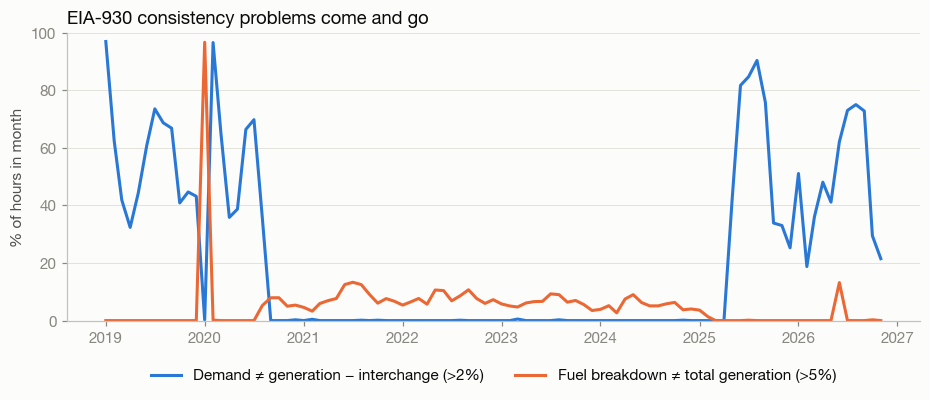

In [4]:
m = df.set_index("datetime_local")[["qa_balance_mismatch", "qa_fuel_sum_mismatch"]].resample("MS").mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
labels = {"qa_balance_mismatch": "Demand ≠ generation − interchange (>2%)",
          "qa_fuel_sum_mismatch": "Fuel breakdown ≠ total generation (>5%)"}
for i, (c, lab) in enumerate(labels.items()):
    ax.plot(m.index, m[c], color=SLOTS[i], label=lab)
ax.set_ylabel("% of hours in month")
ax.set_ylim(0, 100)
ax.set_title("EIA-930 consistency problems come and go")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
save(fig, "01_quality_flags")

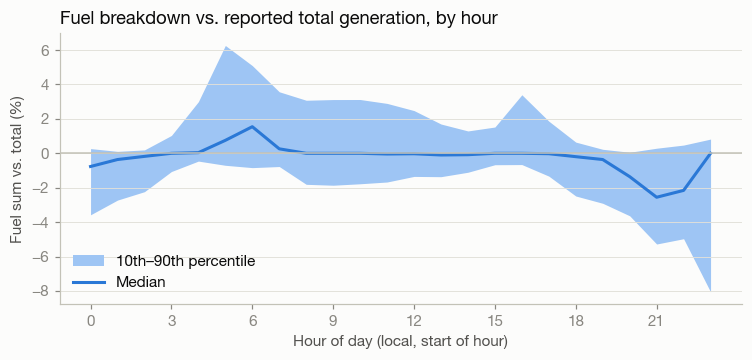

In [5]:
r = (df.fuel_sum_mw - df.net_gen_mw) / df.net_gen_mw * 100
q = r.groupby(df.hour_local).quantile([.1, .5, .9]).unstack()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.fill_between(q.index, q[.1], q[.9], color=BLUE_RAMP[2], lw=0, label="10th–90th percentile")
ax.plot(q.index, q[.5], color=SLOTS[0], label="Median")
ax.axhline(0, color=AXIS, lw=1)
ax.set_xlabel("Hour of day (local, start of hour)"); ax.set_ylabel("Fuel sum vs. total (%)")
ax.set_title("Fuel breakdown vs. reported total generation, by hour")
ax.legend(loc="lower left"); ax.set_xticks(range(0, 24, 3))
save(fig, "01_fuel_sum_gap_by_hour")

**Notes.**
- The ± few-percent daily-cycle gap between the fuel breakdown and total generation is a reporting artifact. It barely affects intensity, which depends only on each fuel's *share*.
- January 2020 is the big hole: fuel data cover about 77% of generation, so intensity is blank for most of that month.
- The demand/balance inconsistency in 2019–20 and from mid-2025 affects the demand columns. Be careful using `demand_mw` as a feature in those periods.

## 2. Carbon intensity over time

,mean,std,min,max
year,,,,
2019,383.0,42.0,275.0,497.0
2020,356.0,44.0,244.0,468.0
2021,373.0,48.0,261.0,502.0
2022,364.0,40.0,259.0,482.0
2023,330.0,31.0,244.0,433.0
2024,329.0,40.0,217.0,458.0
2025,343.0,42.0,227.0,451.0
2026,338.0,43.0,209.0,449.0


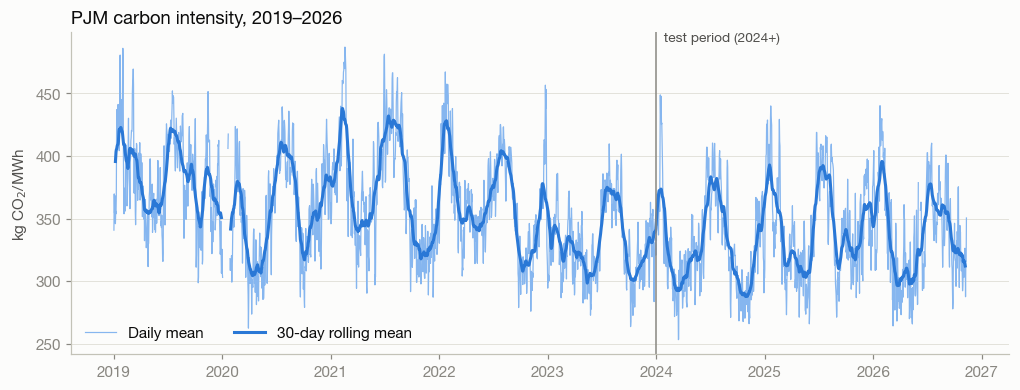

In [6]:
d = df.set_index("datetime_local")[CI].resample("D").mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(d.index, d, color=BLUE_RAMP[3], lw=0.8, label="Daily mean")
ax.plot(d.index, d.rolling(30, center=True, min_periods=20).mean(), color=SLOTS[0], label="30-day rolling mean")
ax.axvline(SPLIT.tz_localize("America/New_York"), color=MUTED, lw=1)
ax.text(SPLIT.tz_localize("America/New_York"), ax.get_ylim()[1], "  test period (2024+)", color=INK2, va="top", fontsize=9)
ax.set_ylabel("kg CO$_2$/MWh"); ax.set_title("PJM carbon intensity, 2019–2026")
ax.legend(loc="lower left", ncol=2)
save(fig, "02_ci_over_time")

yearly = df.groupby("year")[CI].agg(["mean", "std", "min", "max"]).round(0)
yearly

The level drifts by year: a cleaner grid in 2023–24, then up again in 2025 as gas and coal ran more. A model trained on 2019–2023 will see a different average than the test years. Features like "intensity over the last 24 h" let it adapt, while hour-of-day averages alone will not.

## 3. When in the day is the grid cleanest?

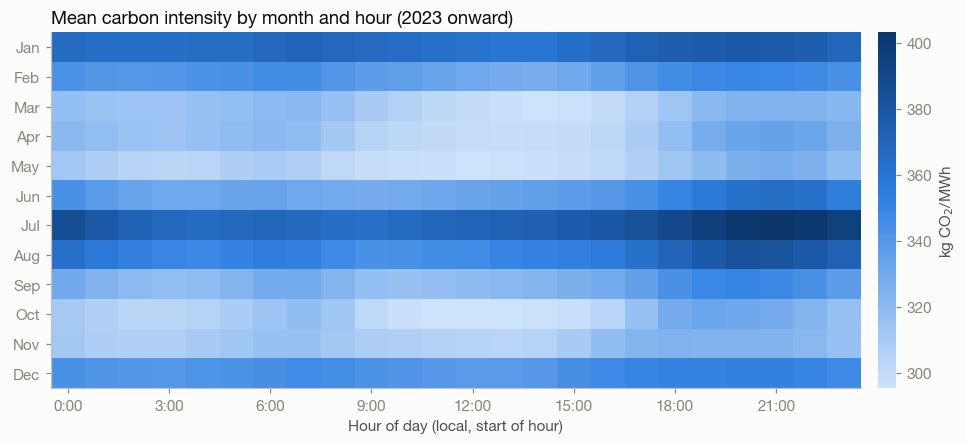

In [7]:
recent = df[df.date_local >= "2023-01-01"]
heat = recent.pivot_table(index="month", columns="hour_local", values=CI, aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(heat.values, aspect="auto", cmap=blue_cmap, origin="upper")
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels([f"{h}:00" for h in range(0, 24, 3)])
ax.set_yticks(range(12)); ax.set_yticklabels(pd.to_datetime(heat.index, format="%m").strftime("%b"))
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label("kg CO$_2$/MWh"); cb.outline.set_visible(False)
ax.set_xlabel("Hour of day (local, start of hour)")
ax.set_title("Mean carbon intensity by month and hour (2023 onward)")
save(fig, "03_heatmap_month_hour")

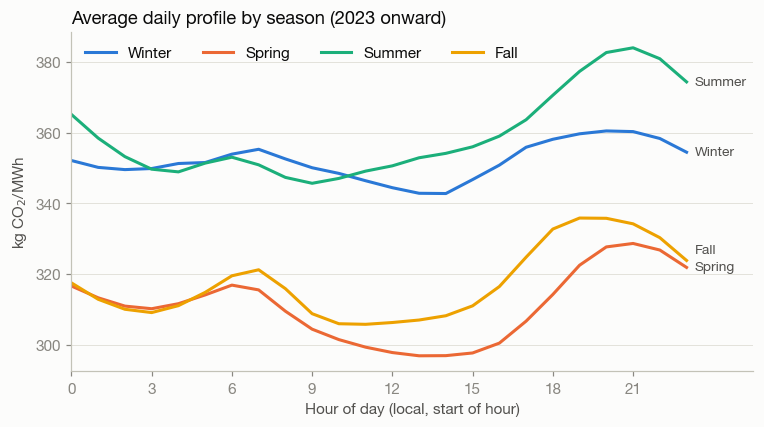

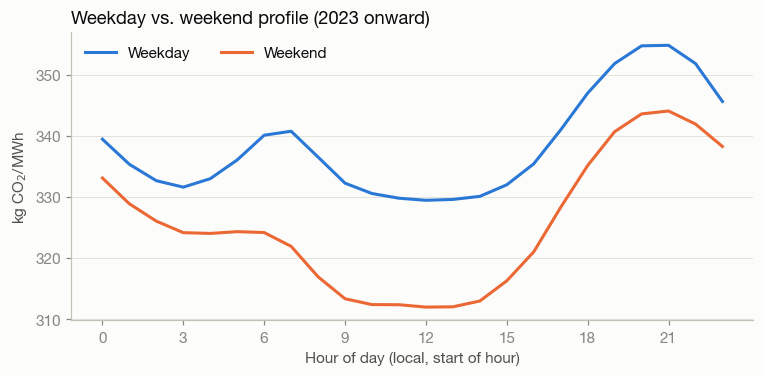

In [8]:
prof = recent.groupby(["season", "hour_local"])[CI].mean().unstack(0)[SEASONS]
fig, ax = plt.subplots(figsize=(8, 4))
ends = prof.iloc[-1].sort_values()
ypos, last = {}, -np.inf
for name, y in ends.items():          # nudge end labels apart so they don't collide
    y = max(y, last + 5); ypos[name] = y; last = y
for i, s in enumerate(SEASONS):
    ax.plot(prof.index, prof[s], color=SLOTS[i], label=s)
    ax.text(23.3, ypos[s], s, color=INK2, va="center", fontsize=9)
ax.set_xlim(0, 25.5); ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (local, start of hour)"); ax.set_ylabel("kg CO$_2$/MWh")
ax.set_title("Average daily profile by season (2023 onward)")
ax.legend(loc="upper left", ncol=4)
save(fig, "03_profile_by_season")

wk = recent.assign(day=np.where(recent.dow >= 5, "Weekend", "Weekday")).groupby(["day", "hour_local"])[CI].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, c in enumerate(["Weekday", "Weekend"]):
    ax.plot(wk.index, wk[c], color=SLOTS[i], label=c)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day (local, start of hour)"); ax.set_ylabel("kg CO$_2$/MWh")
ax.set_title("Weekday vs. weekend profile (2023 onward)"); ax.legend(loc="upper left", ncol=2)
save(fig, "03_profile_weekday_weekend")

## 4. Generation mix

Oil is folded into "Other" for the charts because it's under 1% of generation.

,nuclear,coal,gas,hydro,wind,solar,other
year,,,,,,,
2019,34.0,23.7,35.8,2.0,2.9,0.3,1.4
2020,34.3,19.2,39.6,2.0,2.8,0.4,1.6
2021,32.8,22.1,37.5,2.0,3.4,0.7,1.6
2022,32.4,19.9,39.5,1.9,3.8,0.9,1.6
2023,33.2,14.7,43.8,1.9,3.6,1.1,1.7
2024,32.3,14.5,43.7,1.9,3.7,1.9,2.1
2025,31.0,16.7,42.0,1.8,3.7,2.8,2.1
2026,30.4,16.4,41.2,1.8,3.5,3.6,3.2


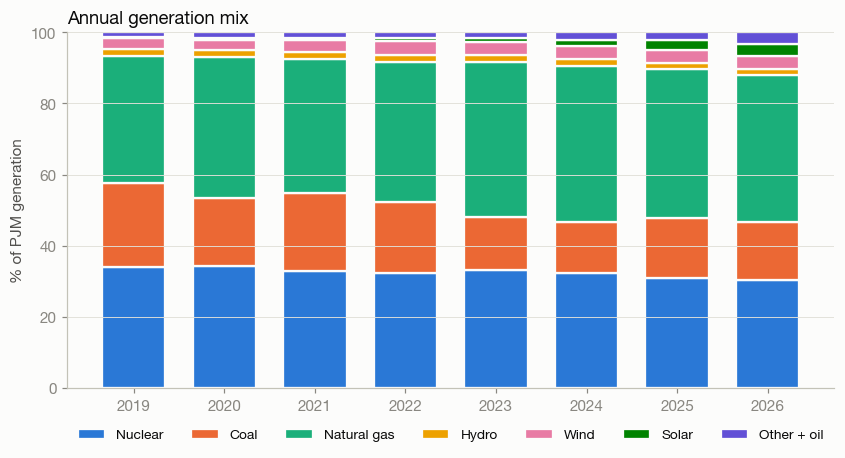

In [9]:
FUEL_ORDER = ["nuclear", "coal", "gas", "hydro", "wind", "solar", "other"]
FUEL_LABEL = {"nuclear": "Nuclear", "coal": "Coal", "gas": "Natural gas", "hydro": "Hydro",
              "wind": "Wind", "solar": "Solar", "other": "Other + oil"}
FUEL_COLOR = dict(zip(FUEL_ORDER, SLOTS))
gen = pd.DataFrame({f: df[f"gen_{f}_mw"].clip(lower=0) for f in FUEL_ORDER})
gen["other"] = gen["other"].fillna(0) + df["gen_oil_mw"].clip(lower=0).fillna(0)
gen.index = df.index

share = gen.groupby(df.year).sum()
share = share.div(share.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
bottom = np.zeros(len(share))
for f in FUEL_ORDER:
    ax.bar(share.index, share[f], bottom=bottom, color=FUEL_COLOR[f], label=FUEL_LABEL[f],
           edgecolor=SURF, linewidth=1.5, width=0.7)
    bottom += share[f].values
ax.set_ylabel("% of PJM generation"); ax.set_ylim(0, 100)
ax.set_title("Annual generation mix")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=7, fontsize=9)
save(fig, "04_annual_mix")
share.round(1)

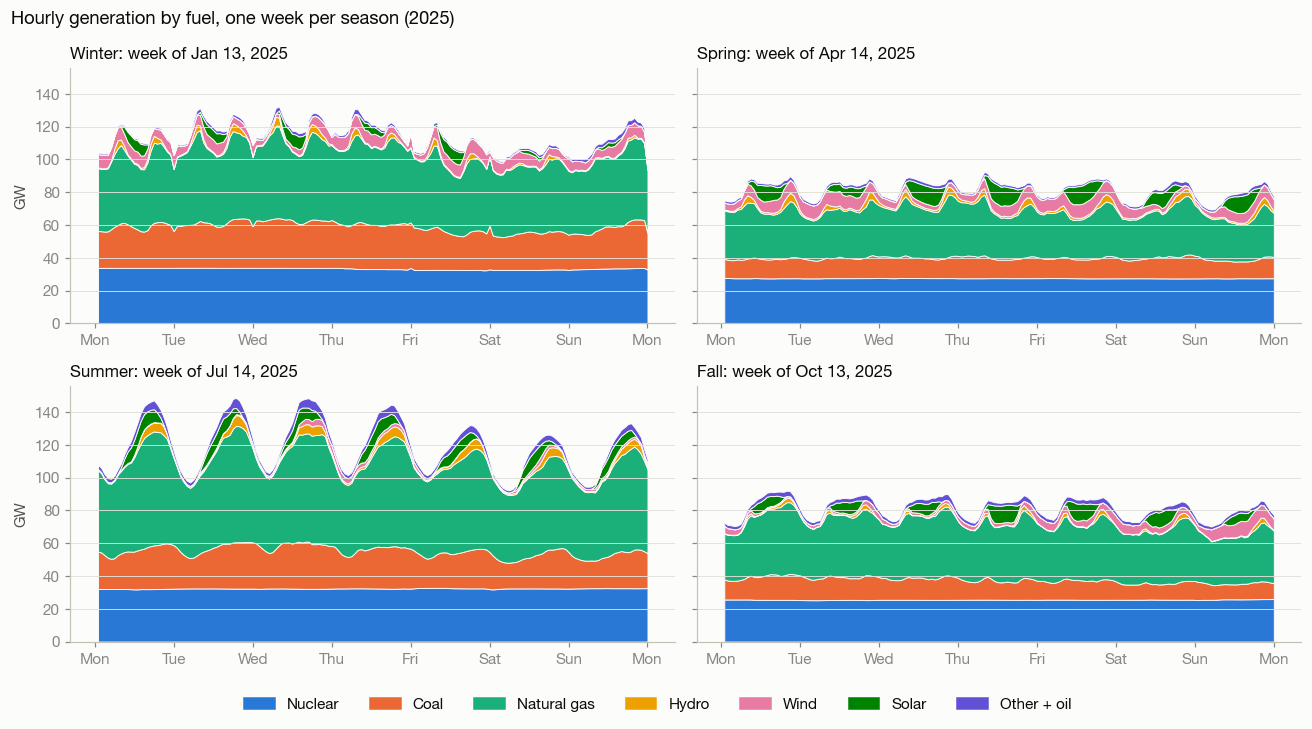

In [10]:
weeks = {"Winter": "2025-01-13", "Spring": "2025-04-14", "Summer": "2025-07-14", "Fall": "2025-10-13"}
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharey=True)
for ax, (s, start) in zip(axes.flat, weeks.items()):
    sel = (df.date_local >= start) & (df.date_local < pd.Timestamp(start) + pd.Timedelta(days=7))
    g = gen[sel] / 1000
    ax.stackplot(df.loc[sel, "datetime_local"], [g[f].fillna(0) for f in FUEL_ORDER],
                 colors=[FUEL_COLOR[f] for f in FUEL_ORDER], edgecolor=SURF, linewidth=0.6)
    ax.set_title(f"{s}: week of {pd.Timestamp(start):%b %d, %Y}", fontsize=11)
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%a", tz="America/New_York"))
for ax in axes[:, 0]: ax.set_ylabel("GW")
handles = [mpl.patches.Patch(color=FUEL_COLOR[f], label=FUEL_LABEL[f]) for f in FUEL_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Hourly generation by fuel, one week per season (2025)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "04_weekly_mix")

Nuclear is a flat base. The daily swings come from gas and coal following demand, and in spring and summer from solar at midday.

## 5. What drives the hour-to-hour swings?

Correlate each variable's *within-day* deviation (value minus that day's mean) with intensity's within-day deviation. This isolates the daily cycle from seasonal and year-to-year level shifts.

Solar output     -0.36
Wind output      -0.32
Nuclear output   -0.10
Temperature       0.12
Hydro output      0.34
Demand            0.51
Gas output        0.61
Coal output       0.79
dtype: float64

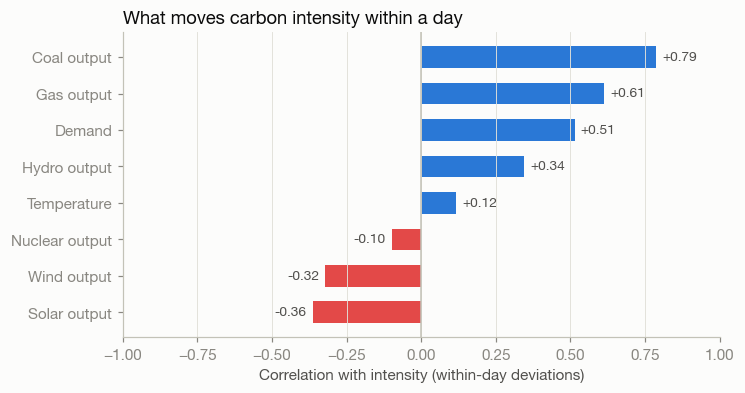

In [11]:
g = df.groupby("date_local")
dev = lambda s: s - s.groupby(df.date_local).transform("mean")
drivers = {"Coal output": gen["coal"], "Gas output": gen["gas"], "Nuclear output": gen["nuclear"],
           "Wind output": gen["wind"], "Solar output": gen["solar"], "Hydro output": gen["hydro"],
           "Demand": df["demand_mw"], "Temperature": df["temp_c"]}
corr = pd.Series({k: dev(df[CI]).corr(dev(v)) for k, v in drivers.items()}).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(corr.index, corr.values, color=[SLOTS[7] if v < 0 else SLOTS[0] for v in corr.values], height=0.6)
ax.axvline(0, color=AXIS, lw=1); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for y, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=INK2)
ax.set_xlim(-1, 1); ax.set_xlabel("Correlation with intensity (within-day deviations)")
ax.set_title("What moves carbon intensity within a day")
save(fig, "05_within_day_drivers")
corr.round(2)

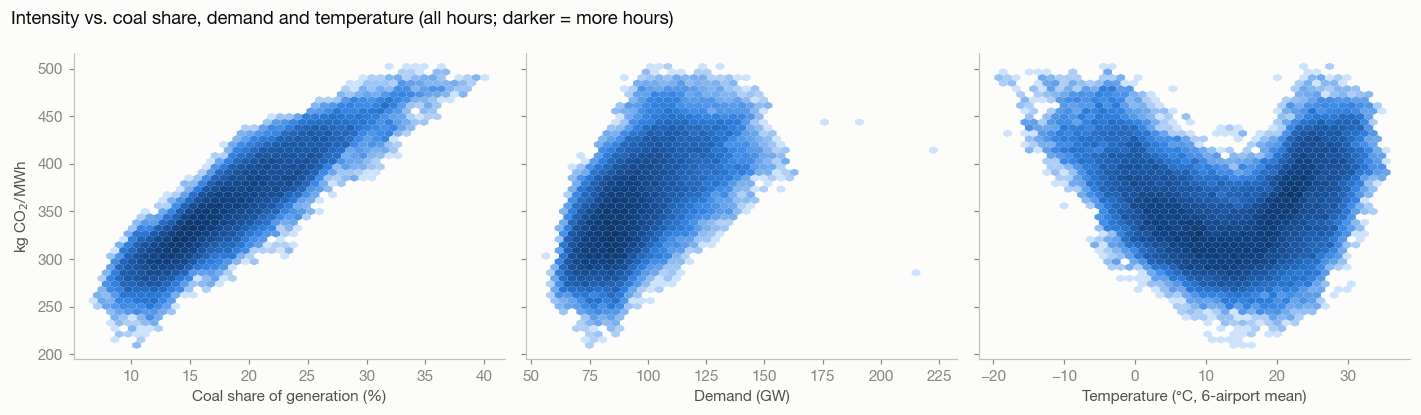

In [12]:
coal_share = gen["coal"] / gen.sum(axis=1) * 100
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (x, lab) in zip(axes, [(coal_share, "Coal share of generation (%)"),
                               (df["demand_mw"] / 1000, "Demand (GW)"),
                               (df["temp_c"], "Temperature (°C, 6-airport mean)")]):
    hb = ax.hexbin(x, df[CI], gridsize=45, cmap=blue_cmap, mincnt=1, bins="log", linewidths=0)
    ax.set_xlabel(lab); ax.grid(False)
axes[0].set_ylabel("kg CO$_2$/MWh")
fig.suptitle("Intensity vs. coal share, demand and temperature (all hours; darker = more hours)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "05_scatter_drivers")

## 6. How much can scheduling save?

The day's spread (dirtiest hour minus cleanest hour) is the most any within-day schedule can save. Only complete days (all 24 hours with intensity) are used.

2,794 complete days
Daily spread: median 46 kg/MWh (13% of the daily mean), 90th pct 75 kg/MWh (22%)


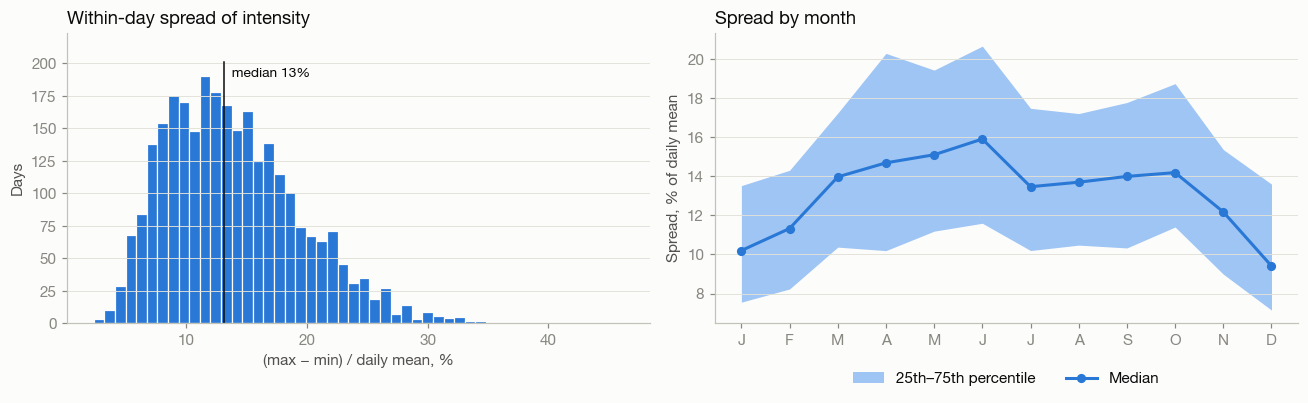

In [13]:
daily = df.pivot_table(index="date_local", columns="hour_local", values=CI, aggfunc="mean").dropna()
spread = daily.max(axis=1) - daily.min(axis=1)
rel = spread / daily.mean(axis=1) * 100
print(f"{len(daily):,} complete days")
print(f"Daily spread: median {spread.median():.0f} kg/MWh ({rel.median():.0f}% of the daily mean), "
      f"90th pct {spread.quantile(.9):.0f} kg/MWh ({rel.quantile(.9):.0f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.hist(rel, bins=50, color=SLOTS[0], edgecolor=SURF, linewidth=0.8)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.axvline(rel.median(), color=INK, lw=1, ymax=0.9)
ax.text(rel.median(), ax.get_ylim()[1] * 0.88, f"  median {rel.median():.0f}%", color=INK, va="top", fontsize=9)
ax.set_xlabel("(max − min) / daily mean, %"); ax.set_ylabel("Days")
ax.set_title("Within-day spread of intensity")
ax = axes[1]
mon = rel.groupby(daily.index.month).quantile([.25, .5, .75]).unstack()
ax.fill_between(mon.index, mon[.25], mon[.75], color=BLUE_RAMP[2], lw=0, label="25th–75th percentile")
ax.plot(mon.index, mon[.5], color=SLOTS[0], marker="o", ms=5, label="Median")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("Spread, % of daily mean"); ax.set_title("Spread by month"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout()
save(fig, "06_daily_spread")

Most common cleanest hour overall: 3 (16% of days)


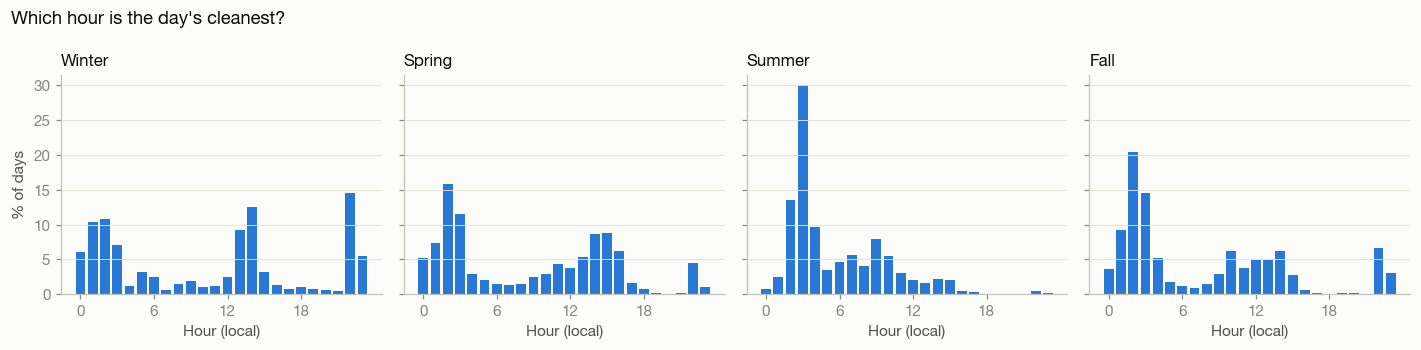

In [14]:
best = daily.idxmin(axis=1)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for i, (ax, s) in enumerate(zip(axes, SEASONS)):
    b = best[daily.index.month.map(SEASON) == s].value_counts(normalize=True).reindex(range(24), fill_value=0) * 100
    ax.bar(b.index, b.values, color=SLOTS[0], width=0.8)
    ax.set_title(s, fontsize=11); ax.set_xticks(range(0, 24, 6)); ax.set_xlabel("Hour (local)")
axes[0].set_ylabel("% of days")
fig.suptitle("Which hour is the day's cleanest?", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "06_cleanest_hour")
print("Most common cleanest hour overall:", best.mode()[0], f"({(best == best.mode()[0]).mean():.0%} of days)")

,night %,midday %
date_local,,
2019,76.0,5.0
2020,75.0,8.0
2021,66.0,14.0
2022,55.0,23.0
2023,56.0,19.0
2024,41.0,33.0
2025,18.0,62.0
2026,7.0,76.0


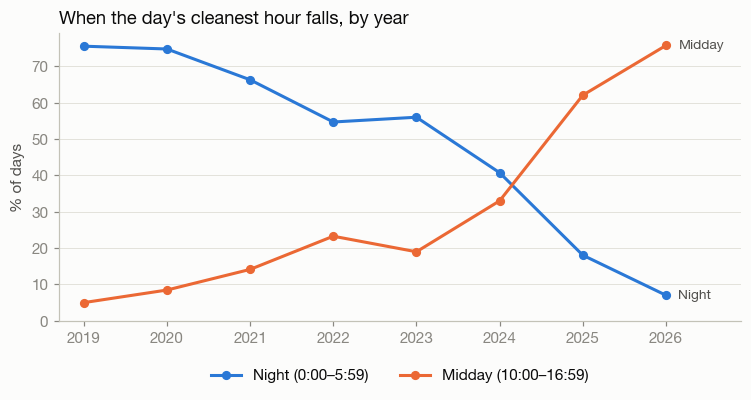

In [15]:
yr = best.groupby(best.index.year)
night = yr.apply(lambda b: b.between(0, 5).mean() * 100)
midday = yr.apply(lambda b: b.between(10, 16).mean() * 100)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(night.index, night, color=SLOTS[0], marker="o", ms=5, label="Night (0:00–5:59)")
ax.plot(midday.index, midday, color=SLOTS[1], marker="o", ms=5, label="Midday (10:00–16:59)")
ax.text(night.index[-1] + 0.15, night.iloc[-1], "Night", color=INK2, va="center", fontsize=9)
ax.text(midday.index[-1] + 0.15, midday.iloc[-1], "Midday", color=INK2, va="center", fontsize=9)
ax.set_xlim(night.index[0] - 0.3, night.index[-1] + 0.9)
ax.set_ylabel("% of days"); ax.set_ylim(0, None)
ax.set_title("When the day's cleanest hour falls, by year")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
save(fig, "06_cleanest_hour_by_year")
pd.DataFrame({"night %": night.round(0), "midday %": midday.round(0)})

### Baseline schedules (preview of the final experiment)

A flexible job of length *k* hours must run sometime within the day. Each policy picks a start hour, evaluated on the test period (2024 onward):

- **Average start hour:** the job lands at a random time of day. This is the reference for savings.
- **Always 9:00:** a typical "run it when the workday starts" choice.
- **Fixed hour:** the start hour with the lowest average intensity in 2019–2023, used every day. No model needed.
- **Yesterday's best:** start at the hour that was cleanest yesterday (persistence).
- **Oracle:** the cleanest window in hindsight (the upper bound).

A forecasting model is only worth it if it beats the fixed hour and yesterday's best.

In [16]:
def window_means(M, k):
    c = np.cumsum(np.pad(M, ((0, 0), (1, 0))), axis=1)
    return (c[:, k:] - c[:, :-k]) / k          # column h = mean intensity of hours h..h+k-1

def evaluate(k, run_now=9):
    W = pd.DataFrame(window_means(daily.values, k), index=daily.index)
    train, test = W[W.index < SPLIT], W[W.index >= SPLIT]
    fixed = int(train.mean().idxmin())
    prev = W.idxmin(axis=1).shift(1).reindex(test.index)
    res = pd.DataFrame({
        "Average start hour": test.mean(axis=1),
        f"Always {run_now}:00": test[run_now],
        f"Fixed hour ({fixed}:00)": test[fixed],
        "Yesterday's best": [test.at[d, int(h)] for d, h in prev.items()],
        "Oracle": test.min(axis=1),
    })
    base, orc = res.iloc[:, 0].mean(), res["Oracle"].mean()
    return pd.DataFrame({
        "mean kg/MWh": res.mean().round(1),
        "saving vs average hour %": ((base - res.mean()) / base * 100).round(1),
        "share of oracle saving %": ((base - res.mean()) / (base - orc) * 100).round(0),
    })

for k in (1, 4):
    print(f"\n{k}-hour job, test period 2024+")
    display(evaluate(k))


1-hour job, test period 2024+


,mean kg/MWh,saving vs average hour %,share of oracle saving %
Average start hour,336.3,0.0,0.0
Always 9:00,326.1,3.1,43.0
Fixed hour (2:00),335.1,0.3,5.0
Yesterday's best,321.9,4.3,60.0
Oracle,312.5,7.1,100.0



4-hour job, test period 2024+


,mean kg/MWh,saving vs average hour %,share of oracle saving %
Average start hour,334.9,0.0,0.0
Always 9:00,324.0,3.3,57.0
Fixed hour (1:00),335.1,-0.1,-1.0
Yesterday's best,322.4,3.7,65.0
Oracle,315.7,5.8,100.0


## 7. How predictable is intensity a day ahead?

Simple forecasts set the bar a model has to beat. Each is scored on the 2024+ test period.

Persistence assumes the forecast is made at the end of today, so every hour of today is known. In practice EIA-930 posts data with a short delay, so these numbers are slightly optimistic.

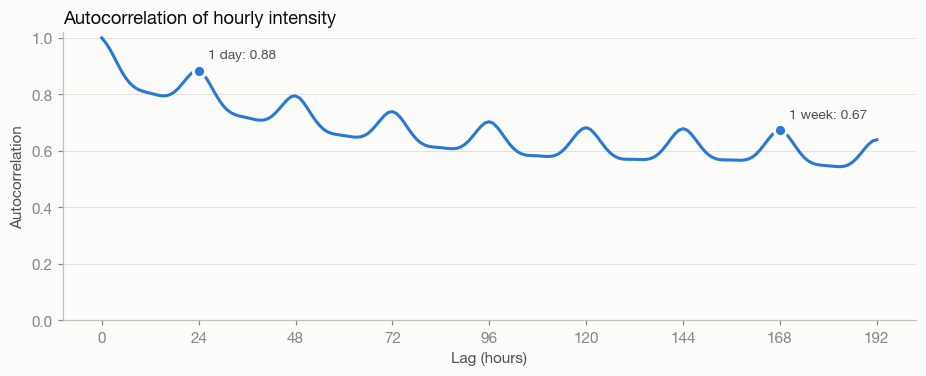

In [17]:
s = df.set_index("datetime_utc")[CI]
a = acf(s.interpolate(limit=6), nlags=24 * 8, missing="conservative")  # tolerates the Jan 2020 gap
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(range(len(a)), a, color=SLOTS[0])
for lag, lab in [(24, "1 day"), (168, "1 week")]:
    ax.plot(lag, a[lag], "o", color=SLOTS[0], ms=8, mec=SURF, mew=2)
    ax.annotate(f"{lab}: {a[lag]:.2f}", (lag, a[lag]), xytext=(6, 8), textcoords="offset points", fontsize=9, color=INK2)
ax.set_xlabel("Lag (hours)"); ax.set_ylabel("Autocorrelation"); ax.set_ylim(0, 1.02)
ax.set_xticks(range(0, 24 * 8 + 1, 24))
ax.set_title("Autocorrelation of hourly intensity")
save(fig, "07_acf")

In [18]:
hours = s.index
test = hours >= SPLIT.tz_localize("UTC")
train_df = df[df.datetime_utc < SPLIT.tz_localize("UTC")]
clim = train_df.groupby(["month", "hour_local"])[CI].mean()
preds = {
    "Same hour yesterday (t−24h)": s.shift(24),
    "Same hour last week (t−168h)": s.shift(168),
    "Mean of same hour, last 7 days": pd.concat([s.shift(24 * i) for i in range(1, 8)], axis=1).mean(axis=1),
    "Climatology (2019–23 month×hour mean)": pd.Series(clim.reindex(pd.MultiIndex.from_arrays([df.month, df.hour_local])).values, index=hours),
}
rows = {}
for name, p in preds.items():
    e = (s - p)[test].dropna()
    rows[name] = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "n hours": len(e)}
scores = pd.DataFrame(rows).T.round(1)
scores["MAE % of mean"] = (scores["MAE"] / s[test].mean() * 100).round(1)
scores

,MAE,RMSE,n hours,MAE % of mean
Same hour yesterday (t−24h),16.7,21.4,24637.0,5.0
Same hour last week (t−168h),29.2,37.6,24493.0,8.7
"Mean of same hour, last 7 days",21.0,26.7,24760.0,6.2
Climatology (2019–23 month×hour mean),36.0,43.9,24784.0,10.7


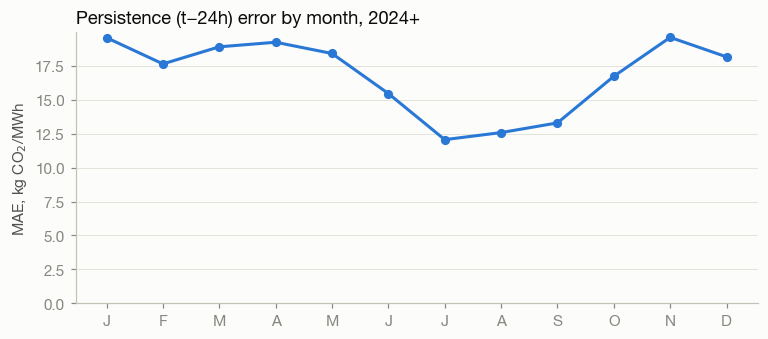

In [19]:
e24 = (s - s.shift(24)).abs()
mae_m = e24[test].groupby(df.set_index("datetime_utc").month[test]).mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(mae_m.index, mae_m.values, color=SLOTS[0], marker="o", ms=5)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("MAE, kg CO$_2$/MWh"); ax.set_ylim(0, None)
ax.set_title("Persistence (t−24h) error by month, 2024+")
save(fig, "07_persistence_by_month")

## 8. Weather and demand

EIA day-ahead demand forecast, mean absolute % error by year (hours without balance flag):


year
2019    2.62
2020    3.49
2021    3.62
2022    3.64
2023    3.45
2024    3.56
2025    3.35
2026    3.43
dtype: float64

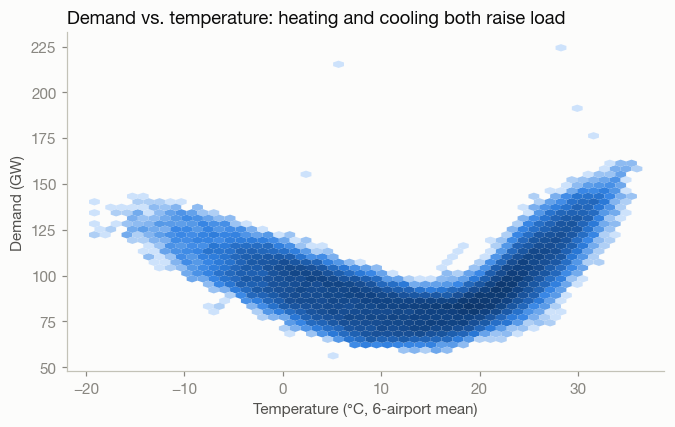

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hexbin(df["temp_c"], df["demand_mw"] / 1000, gridsize=50, cmap=blue_cmap, mincnt=1, bins="log", linewidths=0)
ax.grid(False)
ax.set_xlabel("Temperature (°C, 6-airport mean)"); ax.set_ylabel("Demand (GW)")
ax.set_title("Demand vs. temperature: heating and cooling both raise load")
save(fig, "08_demand_vs_temp")

fc = df.dropna(subset=["demand_mw", "demand_forecast_mw"])
fc = fc[~fc.qa_balance_mismatch]
ape = ((fc.demand_forecast_mw - fc.demand_mw).abs() / fc.demand_mw * 100)
print("EIA day-ahead demand forecast, mean absolute % error by year (hours without balance flag):")
ape.groupby(fc.year).mean().round(2)

**Leakage reminder:** the weather columns are *observed*. For a day-ahead model:
- use lagged weather (yesterday's) as a feature, or
- treat same-day observed weather as an "oracle forecast" upper bound and label it that way.

`demand_forecast_mw` is published a day ahead, so it is a legitimate feature.

## 9. Interchange: does importing power change the picture?

This answers the TA's question with data. If the production- and consumption-based intensities agree and pick the same cleanest hours, the choice of accounting doesn't change the scheduling result.

Consumption − production intensity: mean +0.2, 5th–95th pct -3.8 to +6.4 kg/MWh; correlation 0.9972
Days where both versions pick the same cleanest hour: 84%

Mean production-based intensity of neighbors (kg/MWh):


CPLE    191.0
NYIS    205.0
DUK     274.0
TVA     284.0
CPLW    305.0
MISO    464.0
LGEE    905.0
dtype: float64

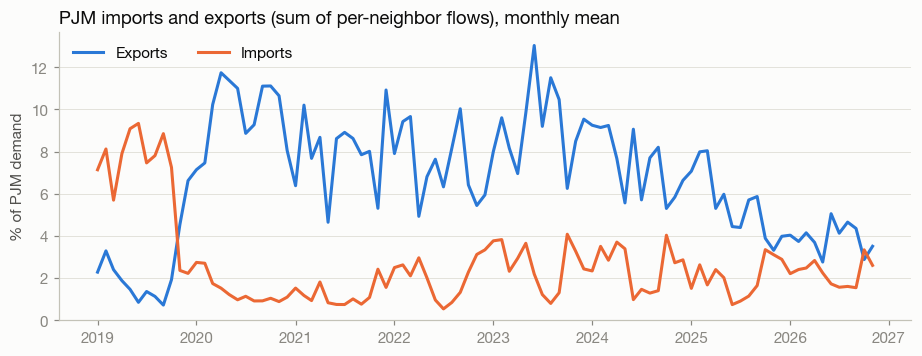

In [21]:
flows = df.set_index("datetime_local")[["imports_mw", "exports_mw", "demand_mw"]].resample("MS").mean()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(flows.index, flows.exports_mw / flows.demand_mw * 100, color=SLOTS[0], label="Exports")
ax.plot(flows.index, flows.imports_mw / flows.demand_mw * 100, color=SLOTS[1], label="Imports")
ax.set_ylabel("% of PJM demand"); ax.set_ylim(0, None)
ax.set_title("PJM imports and exports (sum of per-neighbor flows), monthly mean")
ax.legend(loc="upper left", ncol=2)
save(fig, "09_imports_exports")

diff = df.ci_cons_kg_per_mwh - df[CI]
print(f"Consumption − production intensity: mean {diff.mean():+.1f}, "
      f"5th–95th pct {diff.quantile(.05):+.1f} to {diff.quantile(.95):+.1f} kg/MWh; "
      f"correlation {df[CI].corr(df.ci_cons_kg_per_mwh):.4f}")
daily_c = df.pivot_table(index="date_local", columns="hour_local", values="ci_cons_kg_per_mwh", aggfunc="mean").dropna()
common = daily.index.intersection(daily_c.index)
same = (daily.loc[common].idxmin(axis=1) == daily_c.loc[common].idxmin(axis=1)).mean()
print(f"Days where both versions pick the same cleanest hour: {same:.0%}")
nb = df.filter(regex=r"^ci_(?!prod|cons).*_kg_per_mwh$").mean().round(0)
nb.index = nb.index.str.replace("ci_", "").str.replace("_kg_per_mwh", "")
print("\nMean production-based intensity of neighbors (kg/MWh):"); nb.sort_values()

**Caution on 2019.** In 2019 the per-neighbor flows say PJM was a net *importer* (about 8% of demand). From late 2019 on, it is a steady net exporter. 2019 is also when the demand/balance flag fires most often, so 2019 interchange is probably a reporting problem, not real behavior. Use 2019 cautiously for anything that involves interchange.

There are also a handful of demand values above 175 GW. PJM's all-time peak is around 165 GW, so these are bad data points. Clip or drop them before using demand as a feature.

## Takeaways

Numbers are from the run of this notebook on data through 11 Nov 2026.

**Data quality**
- 1,159 hours (1.7%) have no intensity. 710 are in Jan 2020, when EIA's fuel data cover only about 77% of generation. 372 are hours where EIA filled a gap by copying the previous day's fuel mix (every daylight-saving change, and 2–8 Jun 2026).
- The demand/balance identity fails in much of 2019–20 and from May 2025 on. That affects demand features, not the target.
- 2019 interchange looks wrong: PJM shows up as a net importer. A few demand values above 175 GW are bad data.

**Level and trend**
- Mean intensity fell from 383 kg/MWh (2019) to 328 (2024), then rose to 343 (2025).
- Coal went from 24% of generation (2019) to 15% (2024), then back to 17% (2025). Solar grew from 0.3% to 3.6%.
- The level drifts, so the model needs features that track recent conditions.

**Daily pattern**
- The evening peak (about 18:00–22:00) is the dirtiest time in every season.
- Midday is the cleanest in spring and fall (solar). Summer is cleanest overnight and around 9:00.
- Within a day, intensity moves with coal output (r = +0.79), gas (+0.61) and demand (+0.51), and against solar (−0.36) and wind (−0.32).

**How much there is to gain**
- The median day's spread between cleanest and dirtiest hour is 13% of its mean (22% at the 90th percentile). It is largest in spring and early summer and smallest in winter.
- **The cleanest hour has moved:** it fell at night on 76% of days in 2019 but only 7% in 2026. Midday went from 5% to 76%.
- So a fixed hour learned on 2019–23 (2:00) saves essentially nothing in 2024+ (0.3%).

**Baselines to beat** (1-hour job, test period 2024+, savings relative to a random start hour)

| Policy | Saving | Share of oracle |
|---|---|---|
| Always 9:00 | 3.1% | 43% |
| Yesterday's cleanest hour | 4.3% | 60% |
| Oracle | 7.1% | 100% |

The model has to beat **yesterday's best**, not just "run now".

**Forecast accuracy to beat**
- Autocorrelation at 24 h is 0.89.
- Same-hour-yesterday persistence has MAE 16.7 kg/MWh (5.0% of the mean) and RMSE 21.4.
- Climatology does much worse (MAE 36.0).

**Interchange (TA question)**
- Import-adjusted intensity differs from production-based by +0.2 kg/MWh on average (5th–95th percentile −3.8 to +6.4). The two correlate at 0.997.
- Both pick the same cleanest hour on 84% of days.
- Imports are only about 2% of demand in the median hour, so even dirty neighbors (MISO ≈ 464, LG&E-KU ≈ 905 kg/MWh) barely move PJM's number.
- Production-based accounting is a defensible main target. Report the consumption-based version as a sensitivity check.

### Implications for modeling
1. Use recent-history features (yesterday's 24-hour profile, last week's mean), and consider training on recent years or weighting them more. The solar-driven shift means 2019 patterns are out of date.
2. The scheduler only needs to rank tomorrow's hours correctly. Alongside MAE/RMSE, report *regret*: the intensity of the chosen hour minus the true cleanest hour's.
3. Exclude Jan 2020, and be careful with 2019 interchange and with demand features in the flagged periods.
4. Use `demand_forecast_mw` (MAPE ≈ 3.5%) as a legitimate day-ahead feature. Weather must be lagged.